# Segmentació de VLPs amb una UNet i anàlisi de les proteïnes que hi interaccionen

**Objectiu.** Els vídeos HiLO tenen dos canals un al costat de l'altre (frame de 512 × 1200 px):

* **meitat esquerra** → VLPs (pocs punts, brillants i gairebé immòbils),
* **meitat dreta** → proteïnes (moltes partícules, ja seguides amb u-track: fitxers `*_tracking.txt`).

El pipeline del notebook és:

1. Caracteritzar els VLPs reals (mida del PSF, relació senyal/soroll).
2. Simular imatges de VLPs amb DeepTrack, amb les mateixes estadístiques, i les seves màscares.
3. Entrenar una UNet (deeplay) amb les dades simulades i avaluar-la.
4. Aplicar la UNet al canal de VLPs de tots els vídeos → màscares de VLP per a cada frame.
5. Registrar els dos canals amb la imatge de beads (transformació afí).
6. Portar les trajectòries de les proteïnes a les coordenades dels VLPs i marcar quan estan en contacte.
7. Comparar el comportament (difusió, passos, temps de residència) de les proteïnes en contacte i sense contacte, amb un **control** (màscares girades 180°) per saber què és degut realment als VLPs.

In [1]:
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import deeptrack as dt
import deeplay as dl
from readlif.reader import LifFile
from scipy import ndimage as ndi
from scipy import stats
from scipy.spatial import cKDTree
from skimage import morphology as skmorph
from skimage.feature import peak_local_max
from skimage.measure import label, regionprops, ransac
from skimage.segmentation import expand_labels
from skimage.transform import AffineTransform, warp

In [2]:
#carpeta del projecte (si no existeix, la carpeta des d'on s'executa el notebook)
BASE = Path("/Users/mario/Desktop/UVic/SPT/Projecte Laura")
if not BASE.exists():
    BASE = Path.cwd()

#fitxer LIF i carpeta amb les anàlisis d'u-track de cada projecte
PROJECTES = {
    "P1": ("20241026  Project 1  E1E2 HiLO.lif", "20241026  Project 1  E1E2 HiLO"),
    "P2": ("20241026 Project  2 E1E2 HiLO.lif", "20241026 Project  2 E1E2 HiLO"),
}
SORTIDA = BASE / "resultats"
SORTIDA.mkdir(exist_ok=True)

MEITAT = 600                 #columna on es parteix el frame: esquerra = VLPs, dreta = proteïnes
COLS_VALIDES = (14, 590)     #columnes útils de cada meitat (fora de la franja fosca del divisor d'imatge)
PIXEL_UM = 1 / 9.118252      #µm per píxel (escala que dona el LIF)

IMG = 128                    #mida de les imatges simulades
RADI_MASCARA = 3             #radi (px) de la màscara de cada VLP
MIN_AREA = 4                 #àrea mínima (px) d'una regió predita per considerar-la un VLP
BLOC = 5                     #frames que es promitgen per segmentar els VLPs (més senyal/soroll)
MIN_BLOCS = 3                #un VLP ha d'aparèixer com a mínim en 3 blocs seguits (treu falsos positius)
PIC_MIN = 8                  #senyal/soroll mínim del pic d'un VLP (P10 dels VLPs reals mesurats)
TOLERANCIA = 2               #px que s'afegeixen al voltant de cada VLP per definir "contacte"
MIN_CONTACTE = 3             #frames seguits en contacte perquè una trajectòria "interaccioni"
MIN_PUNTS_MSD = 10           #punts mínims d'una trajectòria per calcular-ne D i alpha

torch.manual_seed(0)
np.random.seed(0)

## 1. Dades

Cada carpeta `seq_sXX` correspon a la sèrie `XX-1` del fitxer LIF (ho he comprovat mirant que les deteccions d'u-track del primer frame cauen sobre els punts brillants de la imatge). Les sèries de beads i de camp clar (BF) no tenen tracking i queden fora automàticament.

In [3]:
_lifs = {}
def obre_lif(path):
    path = str(path)
    if path not in _lifs:
        _lifs[path] = LifFile(path)
    return _lifs[path]

def llista_series():
    files = []
    for proj, (lif_nom, carpeta) in PROJECTES.items():
        for txt in sorted((BASE / carpeta).glob("seq_s*/analysis/*_tracking.txt")):
            s = int(re.search(r"seq_s(\d+)", str(txt)).group(1))
            img = obre_lif(BASE / lif_nom).get_image(s - 1)
            files.append(dict(projecte=proj, serie=s, lif=BASE / lif_nom, idx_lif=s - 1,
                              nom_lif=img.name, frames=img.dims.t, interval=1 / img.scale[3], tracks=txt))
    return pd.DataFrame(files)

def llegeix_frame(img, t):
    return np.asarray(img.get_frame(z=0, t=t, c=0), dtype=np.float32)

series = llista_series()
series[["projecte", "serie", "nom_lif", "frames", "interval"]]

,projecte,serie,nom_lif,frames,interval
0,P1,1,Series002,500,0.041248
1,P1,2,Series001,500,0.030058
2,P1,3,Series003,500,0.030060
3,P1,4,Series004,500,0.030058
4,P2,1,Series001,500,0.030060
5,P2,2,Series002,500,0.030058
6,P2,3,Series003,500,0.030060
7,P2,4,Series004,500,0.030058
8,P2,5,Series005,500,0.030058
9,P2,6,Series006,500,0.030060


In [4]:
#comprovació: les deteccions d'u-track del frame 1 han de caure sobre punts brillants de la sèrie LIF corresponent
def puntuacio_correspondencia(fila, idx_lif):
    f = llegeix_frame(obre_lif(fila.lif).get_image(idx_lif), 0)
    hp = f - ndi.gaussian_filter(f, 5)
    t = pd.read_csv(fila.tracks, sep=r"\s+", header=None)
    p = t[t[2] == 1]
    yi = np.clip(np.round(p[4] - 1).astype(int), 0, f.shape[0] - 1)
    xi = np.clip(np.round(p[3] - 1).astype(int), 0, f.shape[1] - 1)
    return hp[yi, xi].mean() / hp.std()

fila = series.iloc[0]
for idx in range(3):
    print(f"{fila.projecte} seq_s{fila.serie:02d} vs sèrie LIF {idx}: {puntuacio_correspondencia(fila, idx):.2f}")

P1 seq_s01 vs sèrie LIF 0: 4.36
P1 seq_s01 vs sèrie LIF 1: 0.02


P1 seq_s01 vs sèrie LIF 2: 0.03


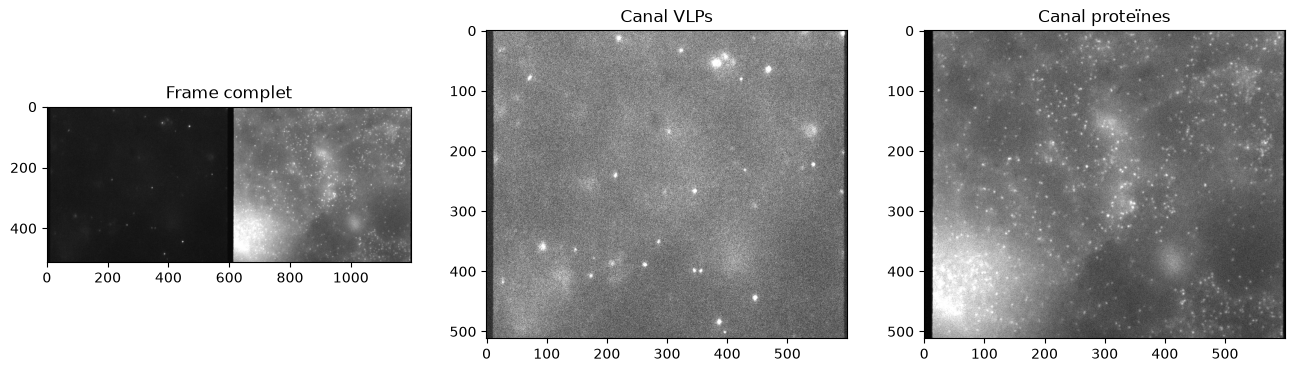

In [5]:
fila = series[(series.projecte == "P1") & (series.serie == 3)].iloc[0]
img_lif = obre_lif(fila.lif).get_image(fila.idx_lif)
frame = llegeix_frame(img_lif, 0)
vlp_channel = frame[:, :MEITAT]
proteines_channel = frame[:, MEITAT:]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].imshow(frame, cmap="gray", vmax=np.percentile(frame, 99.5));   ax[0].set_title("Frame complet")
ax[1].imshow(vlp_channel, cmap="gray", vmax=np.percentile(vlp_channel, 99.8)); ax[1].set_title("Canal VLPs")
ax[2].imshow(proteines_channel, cmap="gray", vmax=np.percentile(proteines_channel, 99.5)); ax[2].set_title("Canal proteïnes")
plt.show()

## 2. Com són els VLPs reals?

Abans la simulació no s'assemblava a les dades (sobretot l'histograma d'intensitats), i per això a les imatges reals la UNet trobava poques coses. La solució és:

* **normalitzar igual les imatges reals i les simulades**: restar el fons (filtre gaussià ample) i dividir pel soroll (desviació robusta, MAD). Així la imatge queda en unitats de "senyal/soroll" i no depèn de la càmera ni del nivell de fons;
* mesurar sobre els VLPs reals l'amplada del PSF i l'amplitud en aquestes unitats, i fer servir aquests valors a la simulació.

531 punts ajustats
sigma PSF (px): mediana 1.56  (P10-P90: 1.28-2.44)
amplitud (senyal/soroll): mediana 23.5  (P10-P90: 8.3-91.6)


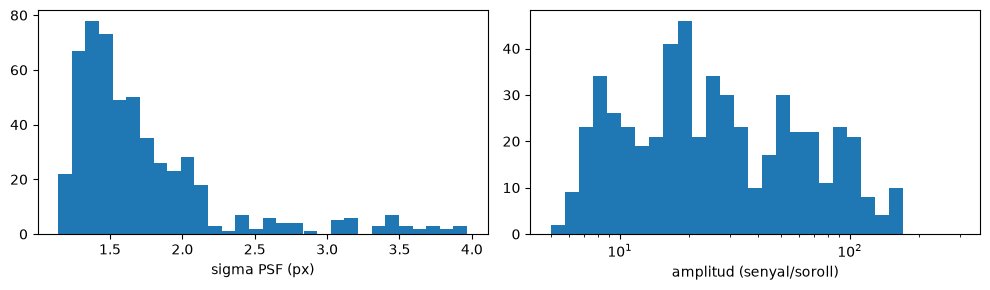

In [6]:
def normalitza(img, sigma_fons=15):
    #treu el fons lent i divideix pel soroll -> unitats de senyal/soroll
    img = np.asarray(img, dtype=np.float32)
    if img.ndim == 3:
        img = img[..., 0]
    res = img - ndi.gaussian_filter(img, sigma_fons)
    sd = 1.4826 * np.median(np.abs(res - np.median(res)))
    return (res / max(sd, 1e-6))[..., None].astype(np.float32)

def gaussiana(xy, A, x0, y0, s, c):
    x, y = xy
    return (A * np.exp(-((x - x0) ** 2 + (y - y0) ** 2) / (2 * s * s)) + c).ravel()

def mesura_punts(img_norm, llindar=6, r=5):
    #ajusta una gaussiana a cada màxim local -> (sigma, amplitud en unitats de soroll)
    from scipy.optimize import curve_fit
    pk = peak_local_max(ndi.gaussian_filter(img_norm, 1), min_distance=4, threshold_abs=llindar, exclude_border=r + 1)
    yy, xx = np.mgrid[-r:r + 1, -r:r + 1]
    out = []
    for y, x in pk:
        c = img_norm[y - r:y + r + 1, x - r:x + r + 1]
        try:
            p, _ = curve_fit(gaussiana, (xx, yy), c.ravel(), p0=[c.max(), 0, 0, 1.5, 0])
        except RuntimeError:
            continue
        if 0.7 < abs(p[3]) < 4 and p[0] > 0:
            out.append((abs(p[3]), p[0]))
    return np.array(out)

x0, x1 = COLS_VALIDES
mesures = []
for t0 in range(0, 100, BLOC):   #els primers 20 blocs de 5 frames
    bloc = np.mean([llegeix_frame(img_lif, t)[:, x0:x1] for t in range(t0, t0 + BLOC)], 0)
    mesures.append(mesura_punts(normalitza(bloc)[..., 0]))
mesures = np.concatenate(mesures)
print(f"{len(mesures)} punts ajustats")
print(f"sigma PSF (px): mediana {np.median(mesures[:, 0]):.2f}  (P10-P90: {np.percentile(mesures[:, 0], 10):.2f}-{np.percentile(mesures[:, 0], 90):.2f})")
print(f"amplitud (senyal/soroll): mediana {np.median(mesures[:, 1]):.1f}  (P10-P90: {np.percentile(mesures[:, 1], 10):.1f}-{np.percentile(mesures[:, 1], 90):.1f})")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(mesures[:, 0], bins=30); ax[0].set_xlabel("sigma PSF (px)")
ax[1].hist(mesures[:, 1], bins=np.logspace(np.log10(5), np.log10(300), 30)); ax[1].set_xscale("log"); ax[1].set_xlabel("amplitud (senyal/soroll)")
plt.tight_layout(); plt.show()

## 3. Simulació amb DeepTrack

* PSF: amb píxel de 0.11 µm, NA = 0.75 i λ = 600 nm DeepTrack dona una sigma ≈ 1.5 px, igual que la mesurada.
* Amplitud dels VLPs: log-uniforme entre 4 i 80 (en unitats de soroll), que cobreix el rang real.
* Fons: gradient + taques difuses grans (com les que es veuen al canal de VLPs, que **no** s'han de segmentar) + soroll gaussià.
* La màscara és un disc de radi `RADI_MASCARA` al voltant de cada VLP.

In [7]:
optics = dt.Fluorescence(
    wavelength=600 * dt.units.nm, NA=0.75, magnification=1,
    resolution=PIXEL_UM * dt.units.um, output_region=(0, 0, IMG, IMG),
)
#amplitud del pic per a intensitat 1 -> així podem fixar l'amplitud directament en unitats de soroll
AMP_UNITAT = np.array(optics(dt.PointParticle(position=(IMG / 2, IMG / 2), intensity=1, z=0))()).max()

particle = dt.PointParticle(
    position=lambda: np.random.uniform(2, IMG - 2, size=2),
    intensity=lambda: np.exp(np.random.uniform(np.log(4), np.log(80))) / AMP_UNITAT,
    z=lambda: np.random.uniform(-0.3, 0.3) * dt.units.um,
)
particles = particle ^ (lambda: np.random.randint(1, 10))

def fons_i_soroll(image):
    image = np.asarray(image, dtype=np.float32)
    yy, xx = np.mgrid[:IMG, :IMG]
    fons = np.random.uniform(-0.01, 0.01) * xx + np.random.uniform(-0.01, 0.01) * yy
    for _ in range(np.random.randint(0, 6)):   #taques difuses (VLPs desenfocats, cèl·lula...)
        cy, cx = np.random.uniform(0, IMG, 2)
        s = np.random.uniform(4, 20)
        fons = fons + np.random.uniform(0.5, 8) * np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * s * s))
    return image + fons[..., None] + np.random.normal(0, 1, image.shape).astype(np.float32)

sim_im_pip = optics(particles) >> fons_i_soroll >> normalitza

def get_mask(radius):
    def inner(mask):
        mask = np.sum(mask, -1, keepdims=True) > 0
        mask = np.pad(mask, [(radius + 2, radius + 2), (radius + 2, radius + 2), (0, 0)], mode="constant")
        mask = skmorph.isotropic_dilation(mask, radius=radius)
        return mask[2:-2, 2:-2]
    return inner

sim_mask_pip = (particles
                >> dt.SampleToMasks(get_mask, radius=RADI_MASCARA,
                                    output_region=optics.output_region, merge_method="or")
                >> dt.AsType("float"))
pipeline = sim_im_pip & sim_mask_pip

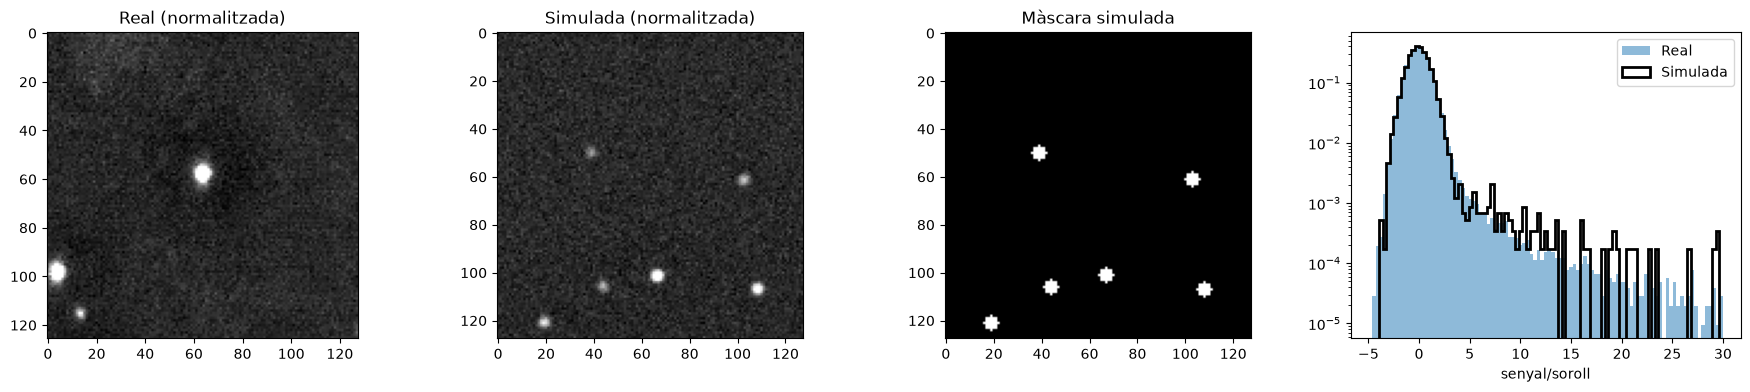

In [8]:
#comparem real vs simulat amb la mateixa normalització
pipeline.update()
sim_im, sim_mask = (np.array(a)[..., 0] for a in pipeline())
real_norm = normalitza(np.mean([llegeix_frame(img_lif, t)[:, x0:x1] for t in range(BLOC)], 0))[..., 0]
y0, xc = 450, 447 - x0   #el VLP que havíem mirat amb Fiji
real_crop = real_norm[y0 - IMG // 2:y0 + IMG // 2, xc - IMG // 2:xc + IMG // 2]

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
ax[0].imshow(real_crop, cmap="gray", vmin=-3, vmax=15); ax[0].set_title("Real (normalitzada)")
ax[1].imshow(sim_im, cmap="gray", vmin=-3, vmax=15);    ax[1].set_title("Simulada (normalitzada)")
ax[2].imshow(sim_mask, cmap="gray");                    ax[2].set_title("Màscara simulada")
ax[3].hist(real_norm.ravel(), bins=np.linspace(-5, 30, 100), density=True, alpha=0.5, label="Real")
ax[3].hist(sim_im.ravel(), bins=np.linspace(-5, 30, 100), density=True, histtype="step", color="k", lw=2, label="Simulada")
ax[3].set_yscale("log"); ax[3].set_xlabel("senyal/soroll"); ax[3].legend()
plt.tight_layout(); plt.show()

## 4. Entrenament de la UNet

Generem un conjunt fix d'imatges simulades (entrenament + validació). Amb CPU l'entrenament triga uns 20 minuts; el model es desa a `resultats/unet_vlp.pt` i, si ja existeix i `ENTRENA = False`, es carrega directament.

In [9]:
def genera(n):
    X = np.zeros((n, 1, IMG, IMG), np.float32)
    Y = np.zeros((n, 1, IMG, IMG), np.float32)
    for i in range(n):
        pipeline.update()
        im, m = pipeline()
        X[i, 0] = np.array(im)[..., 0]
        Y[i, 0] = np.array(m)[..., 0]
    return X, Y

N_TRAIN, N_VAL = 2000, 200
t = time.time()
X_train, Y_train = genera(N_TRAIN)
X_val, Y_val = genera(N_VAL)
print(f"{N_TRAIN + N_VAL} imatges simulades en {time.time() - t:.0f} s")

2200 imatges simulades en 94 s


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss          │ BCEWithLogitsLoss │      0 │ train │     0 │
│ 1 │ train_metrics │ MetricCollection  │      0 │ train │     0 │
│ 2 │ val_metrics   │ MetricCollection  │      0 │ train │     0 │
│ 3 │ test_metrics  │ MetricCollection  │      0 │ train │     0 │
│ 4 │ model         │ UNet2d            │  128 K │ train │     0 │
│ 5 │ optimizer     │ Adam              │      0 │ train │     0 │
└───┴───────────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 128 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 128 K                                                                                                
Total estimated model params size (MB): 0.513                                                                      
Modules in train mode: 42                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

...

Validation DataLoader 0:  75%|███████▌  | 3/4 [00:02<00:00,  1.05it/s]

Validation DataLoader 0: 100%|██████████| 4/4 [00:03<00:00,  1.32it/s]

Epoch 14: 100%|██████████| 63/63 [01:07<00:00,  0.93it/s, v_num=0, train_loss_step=0.00758, val_loss_step=0.00854, val_loss_epoch=0.00863, train_loss_epoch=0.00883]

Epoch 14: 100%|██████████| 63/63 [01:07<00:00,  0.93it/s, v_num=0, train_loss_step=0.00758, val_loss_step=0.00854, val_loss_epoch=0.00863, train_loss_epoch=0.00877]

Epoch 14: 100%|██████████| 63/63 [01:07<00:00,  0.93it/s, v_num=0, train_loss_step=0.00758, val_loss_step=0.00854, val_loss_epoch=0.00863, train_loss_epoch=0.00877]

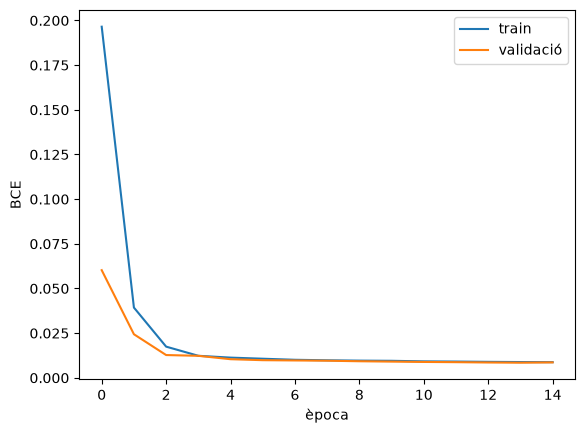

In [10]:
FITXER_MODEL = SORTIDA / "unet_vlp.pt"
ENTRENA = not FITXER_MODEL.exists()

unet = dl.UNet2d(in_channels=1, channels=[16, 32, 64], out_channels=1)
#pos_weight > 1 perquè els píxels de VLP són ~1% de la imatge
unet_reg = dl.Regressor(
    model=unet, loss=torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor(5.0)),
    optimizer=dl.Adam(lr=1e-3),
).create()

if ENTRENA:
    train_loader = dl.DataLoader(torch.utils.data.TensorDataset(torch.from_numpy(X_train), torch.from_numpy(Y_train)),
                                 batch_size=32, shuffle=True)
    val_loader = dl.DataLoader(torch.utils.data.TensorDataset(torch.from_numpy(X_val), torch.from_numpy(Y_val)),
                               batch_size=64)
    unet_trainer = dl.Trainer(max_epochs=15, accelerator="auto")
    unet_trainer.fit(unet_reg, train_loader, val_loader)
    torch.save(unet_reg.model.state_dict(), FITXER_MODEL)
    metrics = pd.read_csv(Path(unet_trainer.logger.log_dir) / "metrics.csv")
    plt.plot(metrics.dropna(subset=["train_loss_epoch"])["epoch"], metrics["train_loss_epoch"].dropna(), label="train")
    plt.plot(metrics.dropna(subset=["val_loss_epoch"])["epoch"], metrics["val_loss_epoch"].dropna(), label="validació")
    plt.xlabel("època"); plt.ylabel("BCE"); plt.legend(); plt.show()
else:
    unet_reg.model.load_state_dict(torch.load(FITXER_MODEL))
    print(f"Model carregat de {FITXER_MODEL}")
model = unet_reg.model.eval()

## 5. Avaluació amb dades simulades

Comptem VLPs, no píxels: una regió predita és un encert si el seu centre és a menys de 3 px d'un VLP real. Triem el llindar de probabilitat que maximitza F1.

In [11]:
def prediu(img, model):
    #probabilitat de VLP per a una imatge 2D (crua); s'omple fins a múltiple de 8 per la UNet
    x = normalitza(img)[..., 0]
    H, W = x.shape
    x = np.pad(x, [(0, -H % 8), (0, -W % 8)], mode="reflect")
    with torch.no_grad():
        p = torch.sigmoid(model(torch.from_numpy(x)[None, None])).numpy()[0, 0]
    return p[:H, :W]

def centroides(mascara):
    return np.array([p.centroid for p in regionprops(label(mascara)) if p.area >= MIN_AREA]).reshape(-1, 2)

def compta_encerts(real, pred, dist=3):
    if len(real) == 0 or len(pred) == 0:
        return 0, len(pred), len(real)
    d, j = cKDTree(real).query(pred, distance_upper_bound=dist)
    tp = len(set(j[np.isfinite(d)]))
    return tp, len(pred) - tp, len(real) - tp

with torch.no_grad():
    P_val = torch.sigmoid(model(torch.from_numpy(X_val))).numpy()

avaluacio = []
for llindar in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    tp = fp = fn = 0
    for i in range(N_VAL):
        a, b, c = compta_encerts(centroides(Y_val[i, 0] > 0.5), centroides(P_val[i, 0] > llindar))
        tp, fp, fn = tp + a, fp + b, fn + c
    avaluacio.append(dict(llindar=llindar, precisio=tp / (tp + fp), sensibilitat=tp / (tp + fn), F1=2 * tp / (2 * tp + fp + fn)))
avaluacio = pd.DataFrame(avaluacio)
LLINDAR = avaluacio.loc[avaluacio.F1.idxmax(), "llindar"]
print(f"Llindar escollit: {LLINDAR}")
avaluacio.round(3)

Llindar escollit: 0.8


,llindar,precisio,sensibilitat,F1
0,0.3,0.981,0.984,0.982
1,0.4,0.985,0.988,0.987
2,0.5,0.987,0.988,0.988
3,0.6,0.989,0.991,0.990
4,0.7,0.988,0.990,0.989
5,0.8,0.990,0.991,0.991
6,0.9,0.981,0.988,0.984


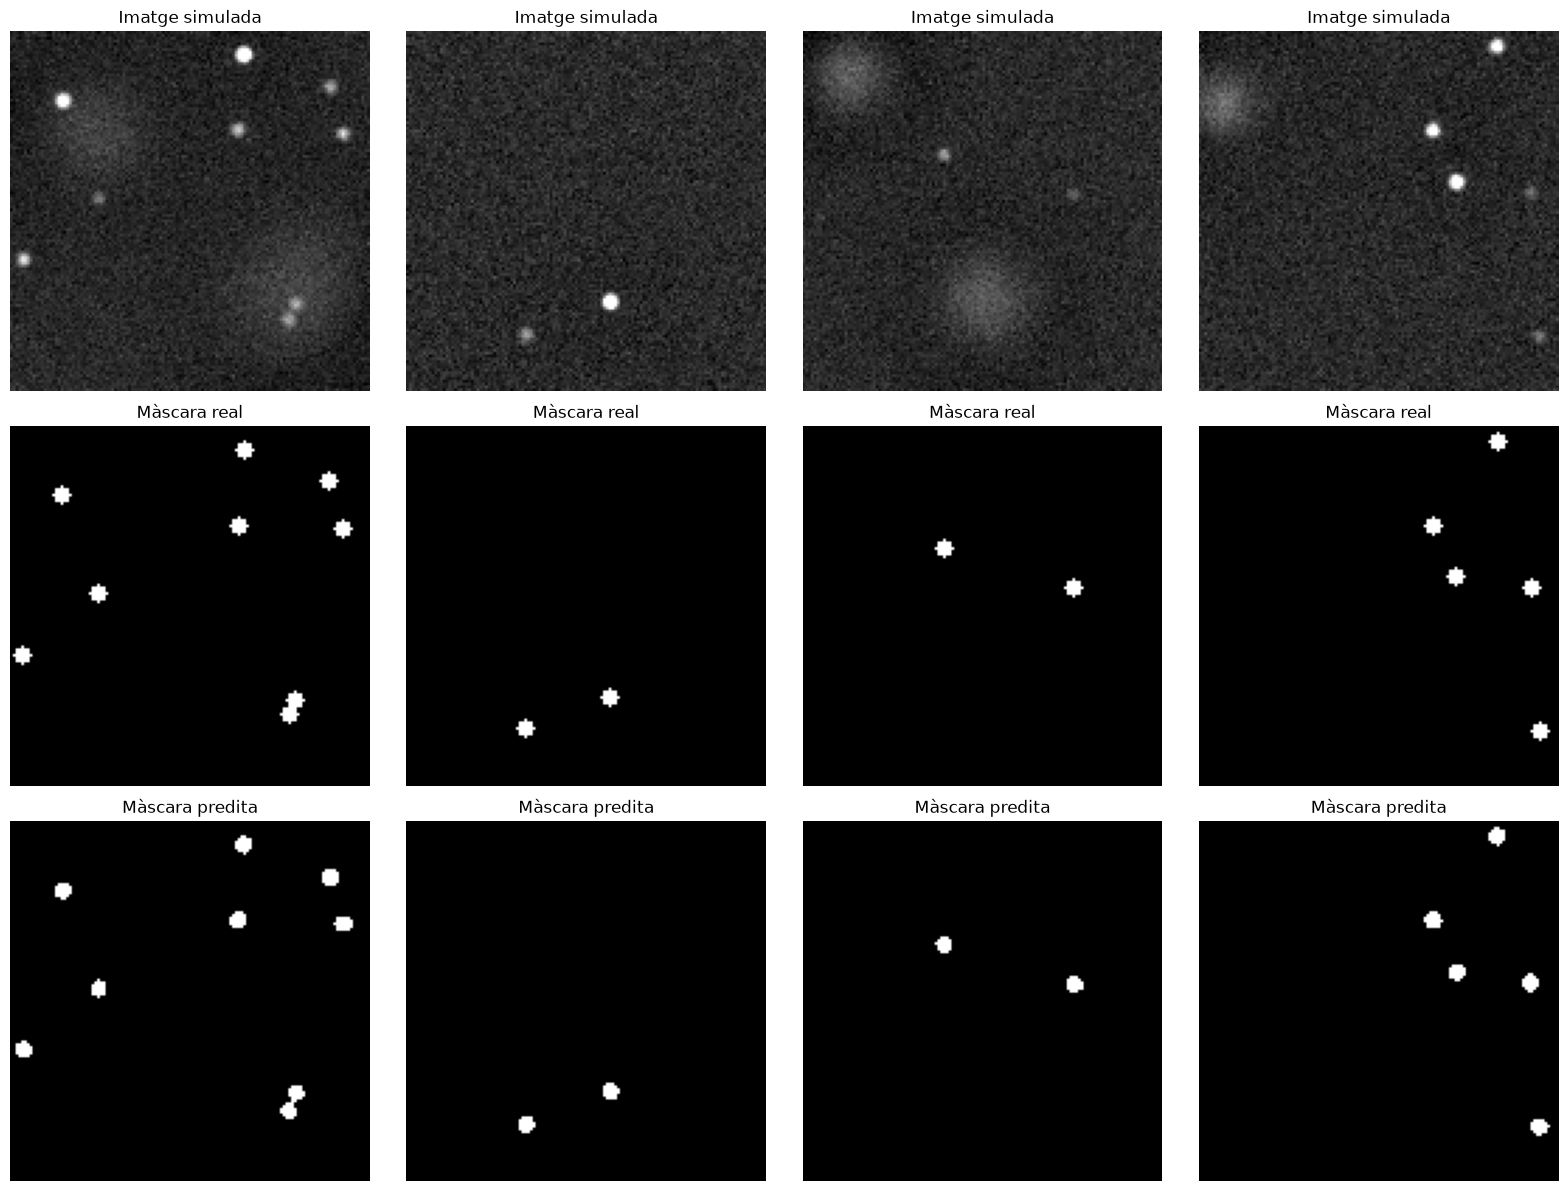

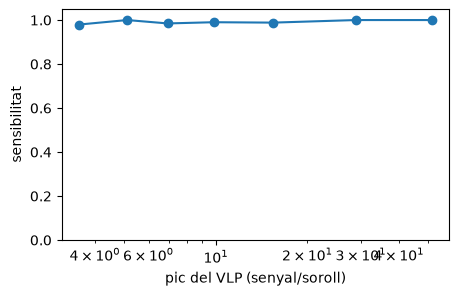

In [12]:
fig, ax = plt.subplots(3, 4, figsize=(16, 12))
for k in range(4):
    ax[0, k].imshow(X_val[k, 0], cmap="gray", vmin=-3, vmax=15); ax[0, k].set_title("Imatge simulada")
    ax[1, k].imshow(Y_val[k, 0], cmap="gray");                    ax[1, k].set_title("Màscara real")
    ax[2, k].imshow(P_val[k, 0] > LLINDAR, cmap="gray");          ax[2, k].set_title("Màscara predita")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()

#sensibilitat en funció de l'amplitud del VLP: quins VLPs se'ns escapen?
X_s, Y_s = genera(300)
with torch.no_grad():
    P_s = torch.sigmoid(model(torch.from_numpy(X_s))).numpy()
amps, trobat = [], []
for i in range(len(X_s)):
    for c in centroides(Y_s[i, 0] > 0.5):
        yy, xx = np.round(c).astype(int)
        amps.append(X_s[i, 0, max(yy - 1, 0):yy + 2, max(xx - 1, 0):xx + 2].max())
        trobat.append(P_s[i, 0, yy, xx] > LLINDAR)
amps, trobat = np.array(amps), np.array(trobat)
bins = np.array([0, 4, 6, 8, 12, 20, 40, 100])
idx = np.digitize(amps, bins)
plt.figure(figsize=(5, 3))
plt.plot([np.mean(amps[idx == i]) for i in range(1, len(bins)) if (idx == i).sum() > 5],
         [np.mean(trobat[idx == i]) for i in range(1, len(bins)) if (idx == i).sum() > 5], "o-")
plt.xscale("log"); plt.xlabel("pic del VLP (senyal/soroll)"); plt.ylabel("sensibilitat"); plt.ylim(0, 1.05)
plt.show()

## 6. Segmentació dels VLPs reals

Per cada vídeo:

1. es promitgen blocs de `BLOC` frames del canal esquerre (els VLPs gairebé no es mouen i així guanyem senyal/soroll),
2. la UNet dona la màscara de cada bloc,
3. s'etiqueten les màscares en 3D (temps, y, x): un VLP és un "tub" connectat en el temps, de manera que cada VLP rep un identificador propi al llarg del vídeo,
4. es descarten les regions massa febles (pic < `PIC_MIN` en senyal/soroll: la UNet també marca punts molt tènues que a les dades reals solen ser soroll) i els VLPs que surten en menys de `MIN_BLOCS` blocs.

Les màscares es guarden a `resultats/mascares/` per no haver-les de tornar a calcular.

In [13]:
def segmenta_vlps(img, model, llindar):
    n, H = img.dims.t, img.dims.y
    x0, x1 = COLS_VALIDES
    mascares = np.zeros((int(np.ceil(n / BLOC)), H, MEITAT), bool)
    for b, t0 in enumerate(range(0, n, BLOC)):
        bloc = np.mean([llegeix_frame(img, t)[:, x0:x1] for t in range(t0, min(t0 + BLOC, n))], 0)
        lab = label(prediu(bloc, model) > llindar)
        if lab.max() == 0:
            continue
        mida = np.bincount(lab.ravel())
        pic = ndi.maximum(normalitza(bloc)[..., 0], lab, np.arange(lab.max() + 1))
        bona = (mida >= MIN_AREA) & (pic >= PIC_MIN)   #treu regions massa petites o massa febles
        bona[0] = False
        mascares[b, :, x0:x1] = bona[lab]
    etiquetes = label(mascares, connectivity=1)
    #filtre de persistència en el temps
    durada = np.zeros(etiquetes.max() + 1, int)
    for p in regionprops(etiquetes):
        durada[p.label] = p.bbox[3] - p.bbox[0]
    durada[0] = 0
    etiquetes[durada[etiquetes] < MIN_BLOCS] = 0
    return etiquetes

def mascares_vlp(fila, model, llindar):
    fitxer = SORTIDA / "mascares" / f"{fila.projecte}_s{fila.serie:02d}.npz"
    if fitxer.exists():
        return np.load(fitxer)["etiquetes"]
    fitxer.parent.mkdir(exist_ok=True)
    etiquetes = segmenta_vlps(obre_lif(fila.lif).get_image(fila.idx_lif), model, llindar)
    np.savez_compressed(fitxer, etiquetes=etiquetes.astype(np.int32))
    return etiquetes

t = time.time()
etiquetes = mascares_vlp(fila, model, LLINDAR)
print(f"{fila.projecte} seq_s{fila.serie:02d}: {len(np.unique(etiquetes)) - 1} VLPs en {time.time() - t:.0f} s")

P1 seq_s03: 73 VLPs en 49 s


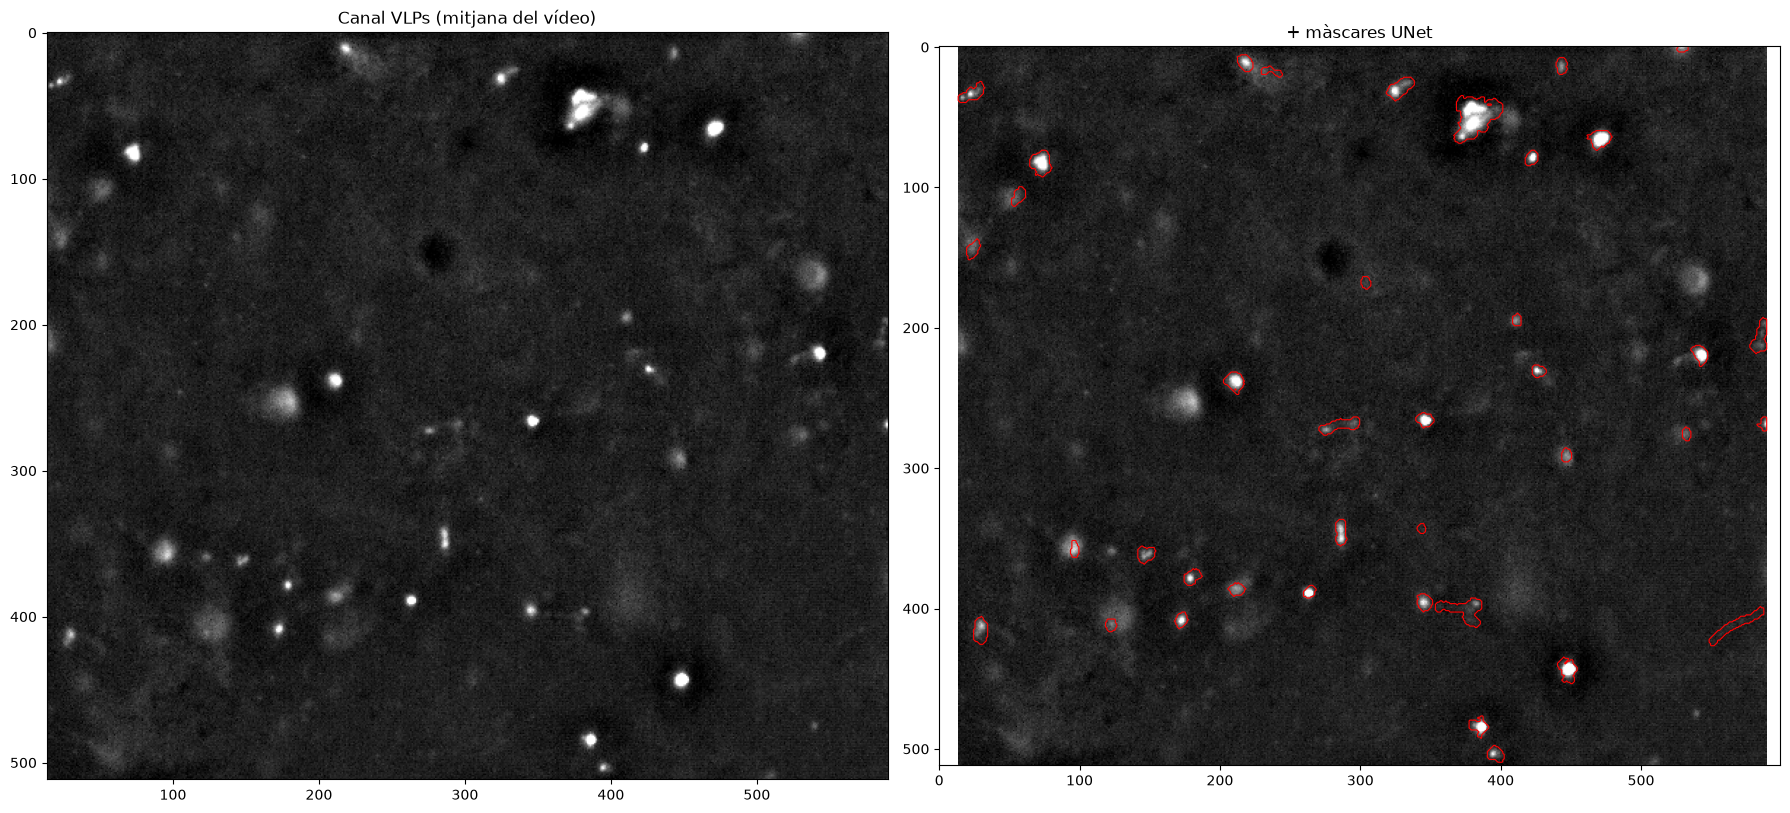

Bloc 0: 26 VLPs UNet, 41 objectes u-track al canal esquerre
VLPs UNet que u-track també detecta: 26/26


In [14]:
#comprovació visual: mitjana del canal de VLPs amb el contorn de les màscares (unió de tots els blocs)
mitjana_vlp = np.mean([llegeix_frame(img_lif, t)[:, :MEITAT] for t in range(0, img_lif.dims.t, 10)], 0)
fig, ax = plt.subplots(1, 2, figsize=(18, 8))
for a in ax:
    a.imshow(normalitza(mitjana_vlp[:, x0:x1])[..., 0], cmap="gray", vmin=-3, vmax=20,
             extent=(x0 - 0.5, x1 - 0.5, mitjana_vlp.shape[0] - 0.5, -0.5))
ax[1].contour((etiquetes > 0).any(0), [0.5], colors="r", linewidths=0.8)
ax[0].set_title("Canal VLPs (mitjana del vídeo)"); ax[1].set_title("+ màscares UNet")
plt.tight_layout(); plt.show()

#concordança amb les deteccions que u-track va fer al canal esquerre (frames 1-5)
trk = pd.read_csv(fila.tracks, sep=r"\s+", header=None)
ut = trk[(trk[2] <= BLOC) & (trk[3] - 0.5 < MEITAT)]
ut = ut.groupby(1)[[4, 3]].mean().to_numpy() - 0.5         #(y, x) de cada objecte, 0-based
unet_c = np.array([p.centroid for p in regionprops(etiquetes[0])]).reshape(-1, 2)
tp, fp, fn = compta_encerts(ut, unet_c)
print(f"Bloc 0: {len(unet_c)} VLPs UNet, {len(ut)} objectes u-track al canal esquerre")
print(f"VLPs UNet que u-track també detecta: {tp}/{len(unet_c)}")

## 7. Registre dels dos canals amb les beads

La imatge `Imatge Inicial beads` (projecte 1) té beads visibles als dos canals. Detectem les beads a cada meitat, les aparellem i ajustem una transformació afí (RANSAC) que porta coordenades del canal dret (proteïnes) al canal esquerre (VLPs).

La imatge de beads és de 1200 × 1200 px però els vídeos són un retall de 512 files (ROI de la càmera, que comença a la fila `RoiLeftHightY` de les metadades). Cal tenir-ho en compte perquè la transformació no és només una translació.

(El projecte 2 no té imatge de beads; és del mateix dia i amb el mateix muntatge, així que fem servir la mateixa transformació.)

In [15]:
def detecta_punts(img, n_sigma=8, sigma_fons=10):
    #màxims locals amb posició subpíxel (centroide 5x5) -> (x, y)
    img = np.asarray(img, np.float32)
    res = img - ndi.gaussian_filter(img, sigma_fons)
    sd = 1.4826 * np.median(np.abs(res - np.median(res)))
    pk = peak_local_max(ndi.gaussian_filter(res, 1), min_distance=3, threshold_abs=n_sigma * sd, exclude_border=3)
    yy, xx = np.mgrid[-2:3, -2:3]
    out = []
    for y, x in pk:
        c = res[y - 2:y + 3, x - 2:x + 3]
        c = c - c.min()
        out.append((x + (c * xx).sum() / c.sum(), y + (c * yy).sum() / c.sum()))
    return np.array(out)

lif_beads = obre_lif(BASE / PROJECTES["P1"][0])
idx_beads = [i for i, im in enumerate(lif_beads.get_iter_image()) if "beads" in im.name.lower()][0]
beads = llegeix_frame(lif_beads.get_image(idx_beads), 0)
p_esq = detecta_punts(beads[:, :MEITAT])
p_dre = detecta_punts(beads[:, MEITAT:])

A_beads = AffineTransform()   #identitat com a punt de partida
for tol in [4, 2, 1.5]:
    d, j = cKDTree(p_esq).query(A_beads(p_dre), distance_upper_bound=tol)
    ok = np.isfinite(d)
    A_beads, inliers = ransac((p_dre[ok], p_esq[j[ok]]), AffineTransform, min_samples=3,
                              residual_threshold=1.5, max_trials=2000, rng=0)
residus = np.linalg.norm(A_beads(p_dre[ok][inliers]) - p_esq[j[ok]][inliers], axis=1)
print(f"{len(p_esq)} / {len(p_dre)} beads; {inliers.sum()} parelles; error RMS = {np.sqrt(np.mean(residus ** 2)):.2f} px")
print(A_beads.params.round(4))

#transformació en coordenades del vídeo: (x, y_vídeo) -> sensor -> afí -> vídeo
m = re.search(r'RoiLeftHightY="(\d+)"', lif_beads.xml_header)
Y_ROI = int(m.group(1)) if m else (beads.shape[0] - img_lif.dims.y) // 2
S = np.array([[1, 0, 0], [0, 1, Y_ROI], [0, 0, 1]], float)
A_video = AffineTransform(matrix=np.linalg.inv(S) @ A_beads.params @ S)
print(f"ROI del vídeo a partir de la fila {Y_ROI}")

171 / 169 beads; 112 parelles; error RMS = 0.74 px
[[ 1.0016e+00  1.8000e-03 -3.4246e+00]
 [ 1.2000e-03  9.9830e-01  2.1095e+00]
 [ 0.0000e+00  0.0000e+00  1.0000e+00]]
ROI del vídeo a partir de la fila 344


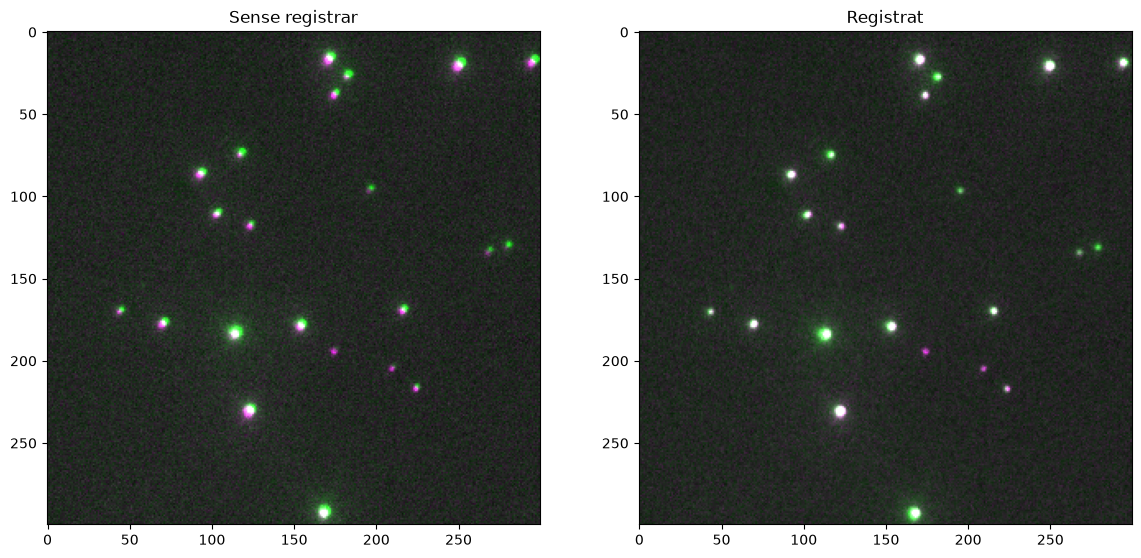

In [16]:
#comprovació: beads del canal esquerre (magenta) i del canal dret registrat (verd)
dreta_reg = warp(beads[:, MEITAT:], A_beads.inverse, preserve_range=True)
def escala(a):
    return np.clip((a - np.percentile(a, 1)) / (np.percentile(a, 99.8) - np.percentile(a, 1)), 0, 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, dreta, tit in [(ax[0], beads[:, MEITAT:], "Sense registrar"), (ax[1], dreta_reg, "Registrat")]:
    rgb = np.dstack([escala(beads[:, :MEITAT]), escala(dreta), escala(beads[:, :MEITAT])])
    a.imshow(rgb[400:700, 200:500]); a.set_title(tit)
plt.show()

## 8. Trajectòries de les proteïnes i contacte amb els VLPs

* Fitxer `*_tracking.txt` d'u-track: columnes `índex, trajectòria, frame, x, y, ...`, en conveni MATLAB (frames des d'1, centre del primer píxel a 0.5 del nostre). Ho passem a 0-based.
* Ens quedem les trajectòries del canal dret senceres (com fa `split_trajs.m`, es descarten les que creuen la frontera) i les portem a coordenades del canal de VLPs amb `A_video`.
* Un punt està **en contacte** si cau dins la màscara d'un VLP en aquell frame, ampliada `TOLERANCIA` px.
* **Control**: el mateix però girant 180° les posicions de les proteïnes dins del camp. Això conserva la densitat i el moviment de les proteïnes però trenca qualsevol relació real amb els VLPs; el que surti en el control és el que esperaríem per atzar.

In [17]:
def carrega_proteines(txt, A):
    df = pd.read_csv(txt, sep=r"\s+", header=None, names=["idx", "track", "frame", "x", "y", "c5", "c6", "amp"])
    df = df[["track", "frame", "x", "y", "amp"]]
    df["frame"] -= 1
    df[["x", "y"]] -= 0.5
    x0, x1 = COLS_VALIDES
    dins = df["x"].between(MEITAT + x0, MEITAT + x1 - 1)
    df = df[dins.groupby(df["track"]).transform("all")].copy()   #trajectòries senceres al canal dret
    df["x"] -= MEITAT
    xy = A(df[["x", "y"]].to_numpy())
    df["xv"], df["yv"] = xy[:, 0], xy[:, 1]
    return df.sort_values(["track", "frame"]).reset_index(drop=True)

def amplia(etiquetes, px):
    return np.stack([expand_labels(e, px) for e in etiquetes])

def contacte(df, etiq_ampl, control=False):
    #identificador del VLP que toca cada punt (0 = cap)
    nb, H, W = etiq_ampl.shape
    x, y = df["xv"].to_numpy(), df["yv"].to_numpy()
    if control:
        x = (COLS_VALIDES[0] + COLS_VALIDES[1] - 1) - x
        y = (H - 1) - y
    xi, yi = np.round(x).astype(int), np.round(y).astype(int)
    b = np.minimum(df["frame"].to_numpy() // BLOC, nb - 1)
    dins = (xi >= 0) & (xi < W) & (yi >= 0) & (yi < H)
    vlp = np.zeros(len(df), np.int32)
    vlp[dins] = etiq_ampl[b[dins], yi[dins], xi[dins]]
    return vlp

def episodis(df, col):
    #trams de frames consecutius en contacte dins de cada trajectòria
    c = (df[col] > 0).to_numpy()
    nou = df["track"].ne(df["track"].shift()) | df["frame"].diff().ne(1) | pd.Series(c).ne(pd.Series(c).shift()).to_numpy()
    grup = nou.cumsum()[c]
    return df[c].groupby(grup.to_numpy()).agg(track=("track", "first"), vlp=(col, "first"),
                                               inici=("frame", "first"), n=("frame", "size")).reset_index(drop=True)

def classifica(df, col):
    #"interacciona": algun episodi >= MIN_CONTACTE frames; "cap contacte": mai toca un VLP; si no, "transitori"
    ep = episodis(df, col)
    max_ep = df["track"].map(ep.groupby("track")["n"].max()).fillna(0)
    return np.where(max_ep >= MIN_CONTACTE, "interacciona", np.where(max_ep > 0, "transitori", "cap contacte")), ep

In [18]:
def msd(x, y, frames, max_lag):
    #MSD d'una trajectòria (x, y en µm); els forats queden com a NaN
    pos = np.full((frames[-1] - frames[0] + 1, 2), np.nan)
    pos[frames - frames[0]] = np.c_[x, y]
    out = np.full(max_lag, np.nan)
    for lag in range(1, max_lag + 1):
        d2 = np.sum((pos[lag:] - pos[:-lag]) ** 2, 1)
        d2 = d2[np.isfinite(d2)]
        if len(d2):
            out[lag - 1] = d2.mean()
    return out

def D_alpha(m, dt):
    #D (µm²/s) amb els 4 primers lags i alpha amb l'ajust log-log
    lags = np.arange(1, len(m) + 1) * dt
    ok = np.isfinite(m) & (m > 0)
    D = np.polyfit(lags[:4][ok[:4]], m[:4][ok[:4]], 1)[0] / 4 if ok[:4].sum() >= 2 else np.nan
    alpha = np.polyfit(np.log(lags[ok]), np.log(m[ok]), 1)[0] if ok.sum() >= 3 else np.nan
    return D, alpha

def resum_trajectories(df, dt):
    files = []
    for tr, g in df.groupby("track", sort=False):
        n = len(g)
        D = alpha = np.nan
        if n >= MIN_PUNTS_MSD:
            m = msd(g["x"].to_numpy() * PIXEL_UM, g["y"].to_numpy() * PIXEL_UM, g["frame"].to_numpy(), min(10, n // 2))
            D, alpha = D_alpha(m, dt)
        files.append((tr, n, D, alpha))
    return pd.DataFrame(files, columns=["track", "n", "D", "alpha"])

def passes(df, dt):
    #desplaçaments entre frames consecutius, etiquetats segons on són
    g = df.groupby("track")
    ok = (g["frame"].diff() == 1).to_numpy()
    r2 = ((g["x"].diff() ** 2 + g["y"].diff() ** 2) * PIXEL_UM ** 2).to_numpy()
    sobre = (df["vlp"] > 0).to_numpy() & (g["vlp"].shift() > 0).to_numpy()
    fora = (df["vlp"] == 0).to_numpy() & (g["vlp"].shift() == 0).to_numpy()
    tipus = np.full(len(df), "", object)
    inter = (df["classe"] == "interacciona").to_numpy()
    tipus[sobre] = "sobre VLP"
    tipus[fora & inter] = "fora (interacciona)"
    tipus[fora & (df["classe"] == "cap contacte").to_numpy()] = "cap contacte"
    sel = ok & (tipus != "")
    return pd.DataFrame({"tipus": tipus[sel], "r": np.sqrt(r2[sel]), "D_pas": r2[sel] / (4 * dt)})

In [19]:
def analitza_serie(fila, model, llindar, A):
    etiquetes = mascares_vlp(fila, model, llindar)
    ampl = amplia(etiquetes, TOLERANCIA)
    df = carrega_proteines(fila.tracks, A)
    resultats = {}
    for cas, control in [("real", False), ("control", True)]:
        d = df.copy()
        d["vlp"] = contacte(d, ampl, control=control)
        d["classe"], ep = classifica(d, "vlp")
        tr = resum_trajectories(d, fila.interval).merge(
            d.groupby("track").agg(classe=("classe", "first"), frac_contacte=("vlp", lambda v: (v > 0).mean())),
            on="track")
        ps = passes(d, fila.interval)
        ep["durada_s"] = ep["n"] * fila.interval
        #enriquiment: densitat de localitzacions dins dels VLPs / densitat fora
        frames = d["frame"].to_numpy()
        area_dins = (ampl > 0).sum((1, 2))[np.minimum(frames // BLOC, len(ampl) - 1)].sum()
        area_total = len(d) * etiquetes.shape[1] * (COLS_VALIDES[1] - COLS_VALIDES[0])
        n_dins = (d["vlp"] > 0).sum()
        enriq = (n_dins / area_dins) / ((len(d) - n_dins) / (area_total - area_dins)) if area_dins else np.nan
        for t in (tr, ps, ep):
            t["projecte"], t["serie"], t["cas"] = fila.projecte, fila.serie, cas
        resultats[cas] = dict(tracks=tr, passes=ps, episodis=ep, df=d, enriquiment=enriq,
                              frac_punts_contacte=n_dins / len(d))
    resultats["n_vlps"] = len(np.unique(etiquetes)) - 1
    resultats["etiquetes"] = etiquetes
    return resultats

t = time.time()
R = analitza_serie(fila, model, LLINDAR, A_video)
print(f"{time.time() - t:.0f} s")
for cas in ["real", "control"]:
    print(f"{cas:8s} punts en contacte: {100 * R[cas]['frac_punts_contacte']:.2f}%   enriquiment: {R[cas]['enriquiment']:.2f}   "
          f"trajectòries: {R[cas]['tracks']['classe'].value_counts().to_dict()}")

10 s
real     punts en contacte: 0.78%   enriquiment: 1.00   trajectòries: {'cap contacte': 6874, 'interacciona': 81, 'transitori': 25}
control  punts en contacte: 0.88%   enriquiment: 1.13   trajectòries: {'cap contacte': 6842, 'interacciona': 84, 'transitori': 54}


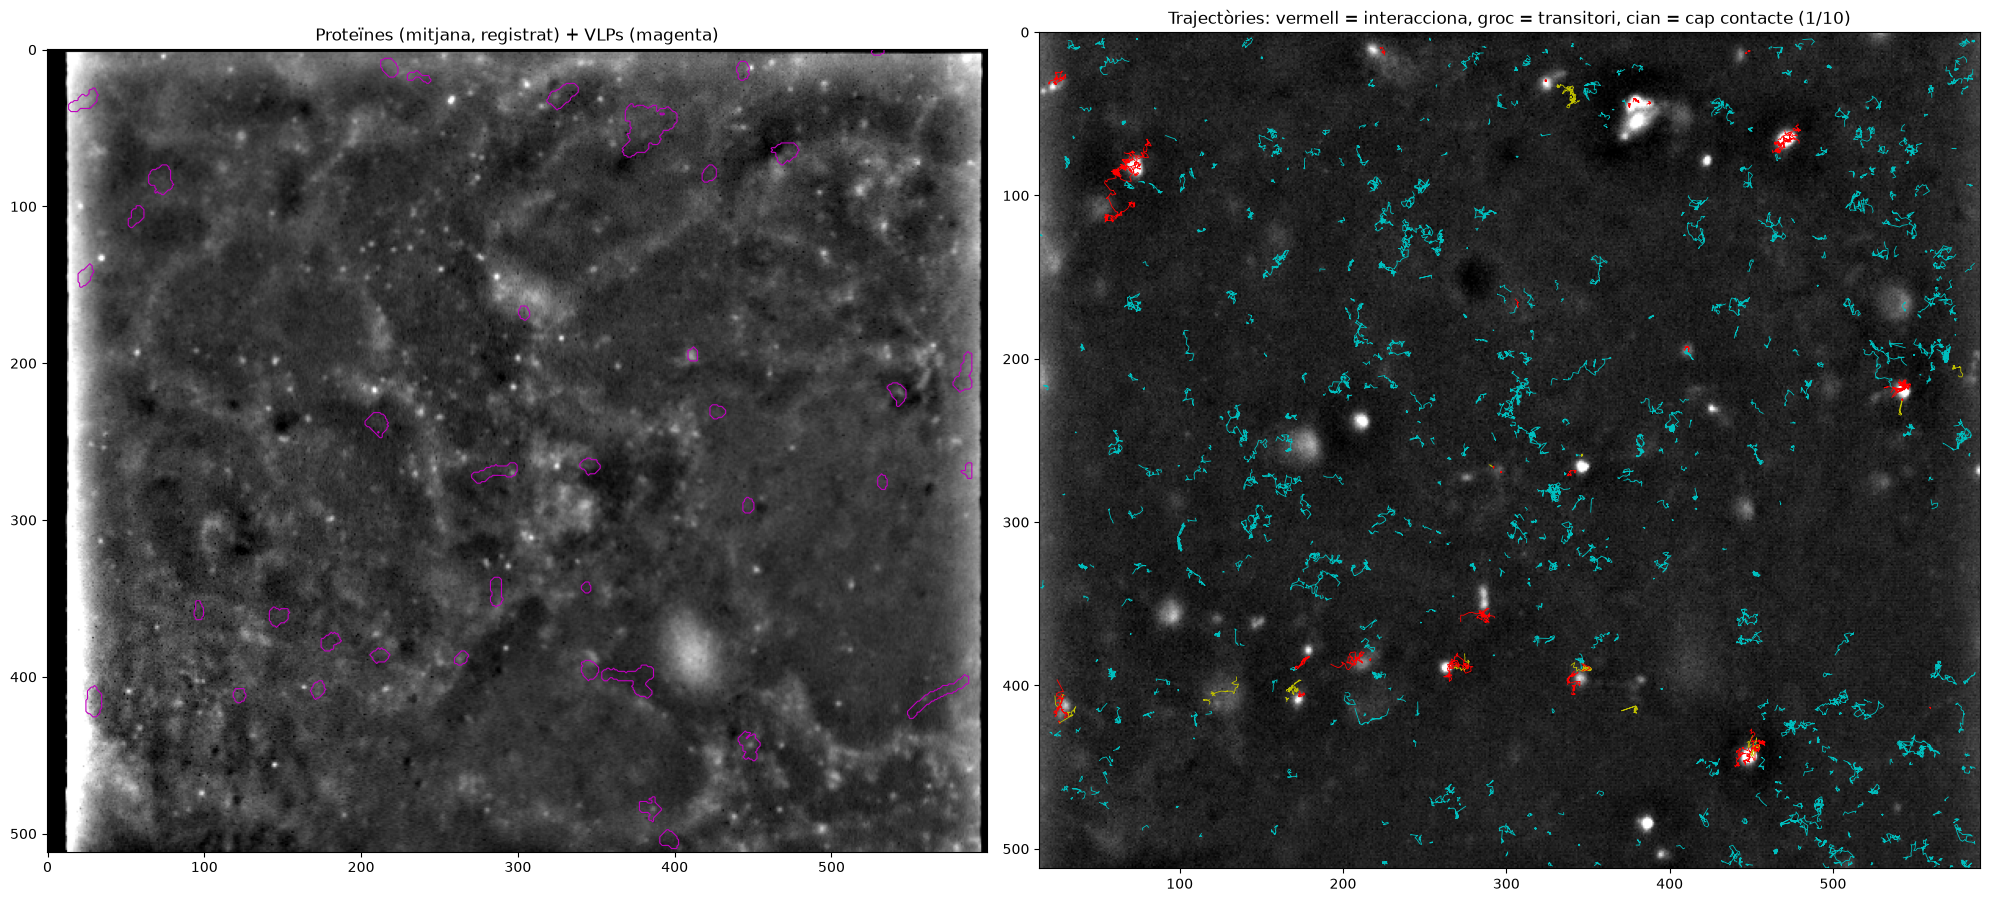

In [20]:
#exemple: canal de proteïnes registrat + contorns dels VLPs + trajectòries (vermell = interacciona)
mitjana_prot = np.mean([llegeix_frame(img_lif, t)[:, MEITAT:] for t in range(0, img_lif.dims.t, 10)], 0)
prot_reg = warp(mitjana_prot, A_video.inverse, preserve_range=True)
d = R["real"]["df"]

fig, ax = plt.subplots(1, 2, figsize=(20, 9))
ax[0].imshow(normalitza(prot_reg)[..., 0], cmap="gray", vmin=-3, vmax=10)
ax[0].contour((R["etiquetes"] > 0).any(0), [0.5], colors="m", linewidths=0.8)
ax[0].set_title("Proteïnes (mitjana, registrat) + VLPs (magenta)")
ax[1].imshow(normalitza(mitjana_vlp)[..., 0], cmap="gray", vmin=-3, vmax=20)
for tr, g in d.groupby("track"):
    cl = g["classe"].iat[0]
    if cl == "cap contacte" and tr % 10:   #només una de cada 10 per no saturar
        continue
    ax[1].plot(g["xv"], g["yv"], lw=0.6, color={"interacciona": "r", "transitori": "y", "cap contacte": "c"}[cl])
ax[1].set_xlim(COLS_VALIDES); ax[1].set_ylim(img_lif.dims.y, 0)
ax[1].set_title("Trajectòries: vermell = interacciona, groc = transitori, cian = cap contacte (1/10)")
plt.tight_layout(); plt.show()

## 9. Totes les sèries

Mateixa anàlisi per a totes les sèries dels dos projectes. Les màscares es reutilitzen si ja estan calculades. Els resultats es guarden a `resultats/*.csv`.

In [21]:
tots_tracks, tots_passes, tots_episodis, resum = [], [], [], []
for fila in series.itertuples():
    t = time.time()
    R = analitza_serie(fila, model, LLINDAR, A_video)
    for cas in ["real", "control"]:
        tots_tracks.append(R[cas]["tracks"])
        tots_passes.append(R[cas]["passes"])
        tots_episodis.append(R[cas]["episodis"])
        cl = R[cas]["tracks"]["classe"].value_counts()
        resum.append(dict(projecte=fila.projecte, serie=fila.serie, cas=cas, n_vlps=R["n_vlps"],
                          trajectories=len(R[cas]["tracks"]), interaccionen=cl.get("interacciona", 0),
                          pct_punts_contacte=100 * R[cas]["frac_punts_contacte"], enriquiment=R[cas]["enriquiment"]))
    print(f"{fila.projecte} seq_s{fila.serie:02d}: {R['n_vlps']} VLPs, {len(R['real']['tracks'])} trajectòries ({time.time() - t:.0f} s)")
    del R

tots_tracks = pd.concat(tots_tracks, ignore_index=True)
tots_passes = pd.concat(tots_passes, ignore_index=True)
tots_episodis = pd.concat(tots_episodis, ignore_index=True)
resum = pd.DataFrame(resum)
tots_tracks.to_csv(SORTIDA / "trajectories.csv", index=False)
tots_episodis.to_csv(SORTIDA / "episodis_contacte.csv", index=False)
resum.to_csv(SORTIDA / "resum_series.csv", index=False)
resum.pivot_table(index=["projecte", "serie", "n_vlps"], columns="cas",
                  values=["interaccionen", "pct_punts_contacte", "enriquiment"]).round(2)

P1 seq_s01: 63 VLPs, 9060 trajectòries (60 s)


P1 seq_s02: 163 VLPs, 6610 trajectòries (52 s)


P1 seq_s03: 73 VLPs, 6980 trajectòries (10 s)


P1 seq_s04: 31 VLPs, 3688 trajectòries (50 s)


P2 seq_s01: 127 VLPs, 2479 trajectòries (61 s)


...

P2 seq_s10: 104 VLPs, 3055 trajectòries (3185 s)


P2 seq_s11: 194 VLPs, 5802 trajectòries (3671 s)


P2 seq_s12: 99 VLPs, 5265 trajectòries (3671 s)


P2 seq_s13: 177 VLPs, 1500 trajectòries (3669 s)


enriquiment       interaccionen         \
cas                       control  real       control   real   
projecte serie n_vlps                                          
P1       1     63            1.19  2.07         107.0  120.0   
         2     163           0.87  6.12         129.0  525.0   
         3     73            1.13  1.00          84.0   81.0   
         4     31            0.83  1.42          20.0   28.0   
P2       1     127           1.13  3.54          50.0  116.0   
         2     98            0.47  1.80          46.0  132.0   
         3     193           0.64  2.61         146.0  490.0   
         4     211           1.21  3.20         100.0  219.0   
         5     172           0.54  5.47          23.0  100.0   
         6     106           0.96  3.29          86.0  158.0   
         7     144           1.43  1.60         362.0  365.0   
         8     142           0.76  3.93          53.0  236.0   
         9     155           1.31  2.45         151.0  201.0   
         10    104           1.30  2.04          61.0   83.0   
         11    194           0.82  2.69         171.0  383.0   
         12    99            1.29  2.96         135.0  252.0   
         13    177           1.05  1.20          49.0   50.0   

                      pct_punts_contacte        
cas                              control  real  
projecte serie n_vlps                           
P1       1     63                   0.71  1.22  
         2     163                  1.43  9.30  
         3     73                   0.88  0.78  
         4     31                   0.28  0.47  
P2       1     127                  1.41  4.28  
         2     98                   0.52  1.97  
         3     193                  1.50  5.82  
         4     211                  2.67  6.77  
         5     172                  0.95  8.92  
         6     106                  1.36  4.50  
         7     144                  2.37  2.65  
         8     142                  1.13  5.55  
         9     155                  2.84  5.16  
         10    104                  1.53  2.36  
         11    194                  1.91  6.00  
         12    99                   2.11  4.69  
         13    177                  1.76  2.00

## 10. Resultats

### 10.1 Les proteïnes s'acumulen sobre els VLPs?

Enriquiment = densitat de localitzacions de proteïna dins dels VLPs / densitat fora. Si les proteïnes no tinguessin cap preferència pels VLPs seria ≈ 1, com en el control.

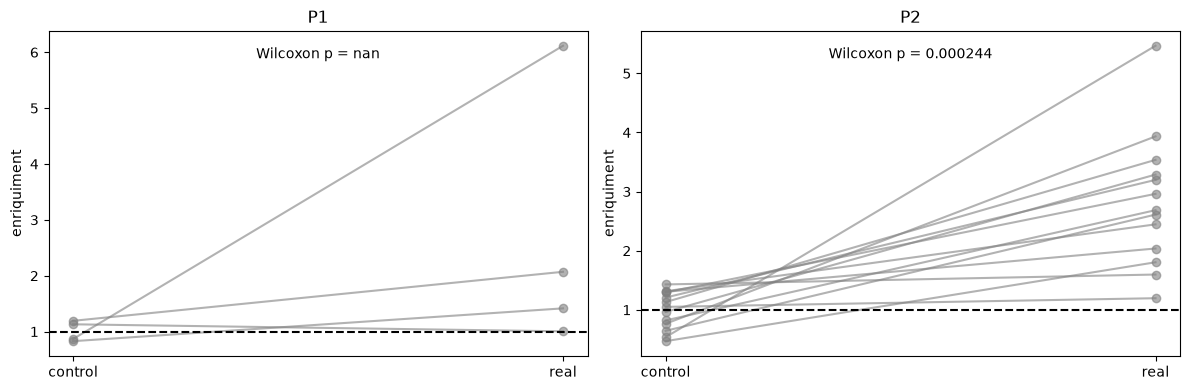

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, (proj, g) in enumerate(resum.groupby("projecte")):
    piv = g.pivot(index="serie", columns="cas", values="enriquiment")
    for s, r in piv.iterrows():
        ax[k].plot([0, 1], [r["control"], r["real"]], "o-", color="gray", alpha=0.6)
    ax[k].axhline(1, ls="--", color="k")
    ax[k].set_xticks([0, 1], ["control", "real"]); ax[k].set_title(proj); ax[k].set_ylabel("enriquiment")
    p = stats.wilcoxon(piv["real"], piv["control"]).pvalue if len(piv) >= 5 else np.nan
    ax[k].text(0.5, 0.95, f"Wilcoxon p = {p:.3g}", transform=ax[k].transAxes, ha="center", va="top")
plt.tight_layout(); plt.show()

### 10.2 Les proteïnes que interaccionen es mouen diferent?

Comparem el coeficient de difusió (D, primers 4 punts del MSD) i l'exponent anòmal (alpha) de les trajectòries:

* *interacciona (real)* vs *cap contacte (real)*: diferència entre proteïnes que toquen VLPs i les que no;
* *interacciona (real)* vs *interacciona (control)*: el control té el mateix biaix (p. ex. les trajectòries llargues toquen més sovint una zona qualsevol), de manera que si la diferència real és més gran que la del control, és deguda als VLPs.

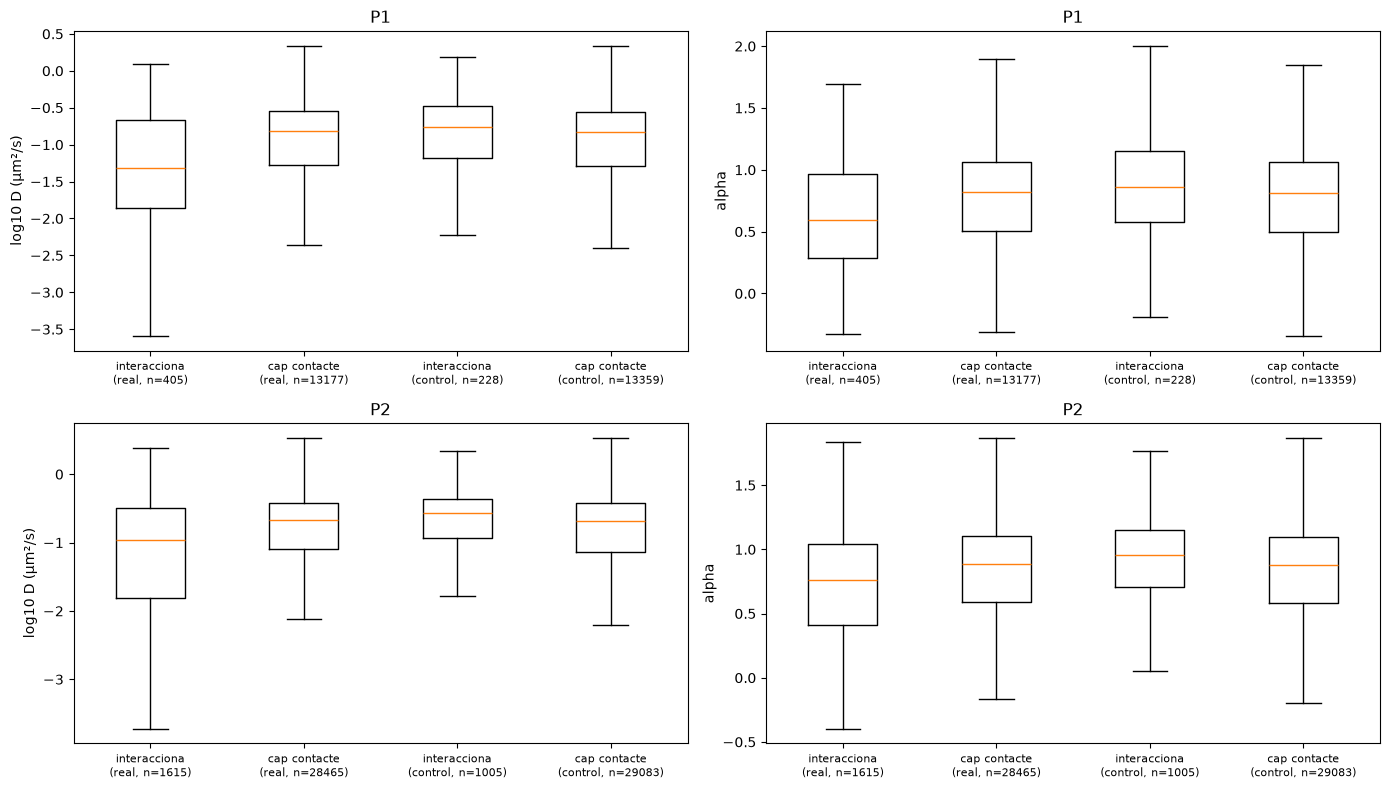

mediana_a  mediana_b     n_a      n_b  \
P1 D     interacciona vs cap contacte     0.0483     0.1529   405.0  13177.0   
         interacciona real vs control     0.0483     0.1736   405.0    228.0   
   alpha interacciona vs cap contacte     0.5902     0.8210   405.0  13177.0   
         interacciona real vs control     0.5902     0.8641   405.0    228.0   
P2 D     interacciona vs cap contacte     0.1096     0.2110  1615.0  28465.0   
         interacciona real vs control     0.1096     0.2679  1615.0   1005.0   
   alpha interacciona vs cap contacte     0.7640     0.8862  1615.0  28465.0   
         interacciona real vs control     0.7640     0.9585  1615.0   1005.0   

                                       p (Mann-Whitney)  
P1 D     interacciona vs cap contacte               0.0  
         interacciona real vs control               0.0  
   alpha interacciona vs cap contacte               0.0  
         interacciona real vs control               0.0  
P2 D     interacciona vs cap contacte               0.0  
         interacciona real vs control               0.0  
   alpha interacciona vs cap contacte               0.0  
         interacciona real vs control               0.0

In [23]:
tt = tots_tracks.dropna(subset=["D"])
tt = tt[tt["D"] > 0]
grups = [("real", "interacciona"), ("real", "cap contacte"), ("control", "interacciona"), ("control", "cap contacte")]

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for i, proj in enumerate(sorted(tt["projecte"].unique())):
    g = tt[tt["projecte"] == proj]
    for j, (var, escala_log) in enumerate([("D", True), ("alpha", False)]):
        dades = [g[(g["cas"] == c) & (g["classe"] == cl)][var] for c, cl in grups]
        ax[i, j].boxplot([np.log10(d) if escala_log else d for d in dades], showfliers=False)
        ax[i, j].set_xticks(range(1, 5), [f"{cl}\n({c}, n={len(d)})" for (c, cl), d in zip(grups, dades)], fontsize=8)
        ax[i, j].set_ylabel("log10 D (µm²/s)" if escala_log else "alpha"); ax[i, j].set_title(proj)
plt.tight_layout(); plt.show()

def compara(a, b):
    return pd.Series({"mediana_a": np.median(a), "mediana_b": np.median(b), "n_a": len(a), "n_b": len(b),
                      "p (Mann-Whitney)": stats.mannwhitneyu(a, b).pvalue})

taula = []
for proj, g in tt.groupby("projecte"):
    for var in ["D", "alpha"]:
        sel = lambda c, cl: g[(g["cas"] == c) & (g["classe"] == cl)][var]
        taula.append(compara(sel("real", "interacciona"), sel("real", "cap contacte")).rename((proj, var, "interacciona vs cap contacte")))
        taula.append(compara(sel("real", "interacciona"), sel("control", "interacciona")).rename((proj, var, "interacciona real vs control")))
pd.DataFrame(taula).round(4)

In [24]:
#el mateix per sèrie (cada sèrie és una rèplica independent): mediana de D de cada grup
med = (tt.groupby(["projecte", "serie", "cas", "classe"])["D"].median().unstack(["cas", "classe"]))
med["ratio real"] = med[("real", "interacciona")] / med[("real", "cap contacte")]
med["ratio control"] = med[("control", "interacciona")] / med[("control", "cap contacte")]
print("D(interacciona) / D(cap contacte) per sèrie")
display(med[["ratio real", "ratio control"]].round(2))
p = stats.wilcoxon(med["ratio real"], med["ratio control"]).pvalue
print(f"Wilcoxon (ratio real vs control, n = {len(med)} sèries): p = {p:.3g}")

D(interacciona) / D(cap contacte) per sèrie


cas            ratio real ratio control
classe                                 
projecte serie                         
P1       1           0.62          1.17
         2           0.25          1.21
         3           0.81          1.04
         4           1.40          1.63
P2       1           0.71          1.18
         2           0.75          1.44
         3           0.62          1.29
         4           0.17          1.27
         5           0.28          1.58
         6           0.57          1.52
         7           0.75          1.23
         8           0.24          1.30
         9           0.47          1.31
         10          1.00          1.65
         11          0.49          1.22
         12          0.45          1.15
         13          1.10          1.97

Wilcoxon (ratio real vs control, n = 17 sèries): p = 1.53e-05


### 10.3 Moviment pas a pas: sobre el VLP vs fora

Dins de les trajectòries que interaccionen separem els passos que fan **sobre** el VLP dels que fan **fora**, i els comparem amb els passos de les trajectòries que no toquen mai cap VLP. `D_pas = r² / (4 Δt)` és un coeficient de difusió instantani.

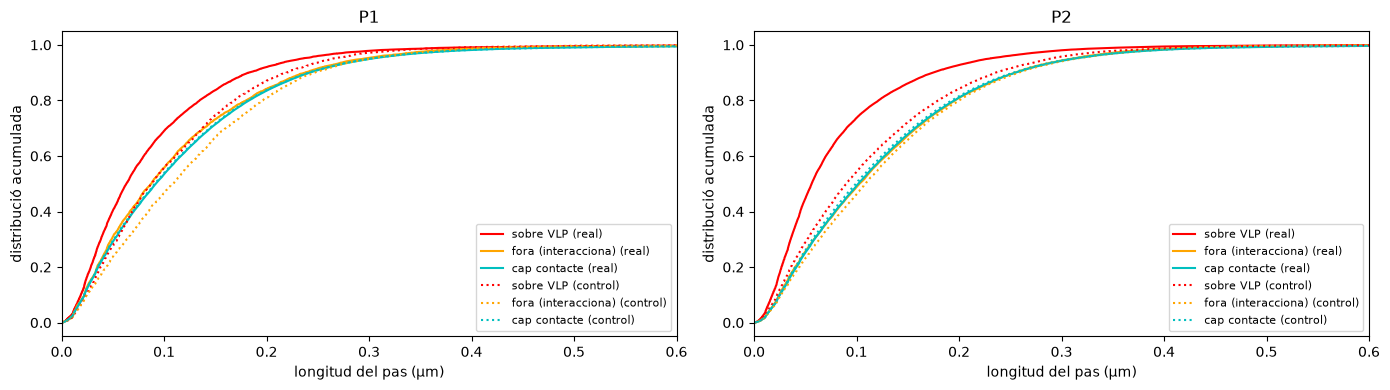

n  pas_mitja_um  D_pas_mitja
projecte cas     tipus                                                  
P1       control cap contacte          451811        0.1173       0.1851
                 fora (interacciona)     3639        0.1263       0.1871
                 sobre VLP               3191        0.1091       0.1449
         real    cap contacte          442342        0.1180       0.1861
                 fora (interacciona)     4593        0.1137       0.1801
                 sobre VLP              10973        0.0877       0.1165
P2       control cap contacte         1015756        0.1238       0.2146
                 fora (interacciona)    22982        0.1291       0.2196
                 sobre VLP              16219        0.1137       0.1778
         real    cap contacte          985709        0.1257       0.2186
                 fora (interacciona)    23900        0.1250       0.2110
                 sobre VLP              43827        0.0804       0.1014

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, proj in enumerate(sorted(tots_passes["projecte"].unique())):
    for cas, estil in [("real", "-"), ("control", ":")]:
        g = tots_passes[(tots_passes["projecte"] == proj) & (tots_passes["cas"] == cas)]
        for tipus, color in [("sobre VLP", "r"), ("fora (interacciona)", "orange"), ("cap contacte", "c")]:
            r = np.sort(g[g["tipus"] == tipus]["r"].to_numpy())
            if len(r):
                ax[k].plot(r, np.arange(1, len(r) + 1) / len(r), estil, color=color, label=f"{tipus} ({cas})")
    ax[k].set_xlabel("longitud del pas (µm)"); ax[k].set_ylabel("distribució acumulada"); ax[k].set_xlim(0, 0.6)
    ax[k].set_title(proj); ax[k].legend(fontsize=8)
plt.tight_layout(); plt.show()

tp = (tots_passes.groupby(["projecte", "cas", "tipus"])
      .agg(n=("r", "size"), pas_mitja_um=("r", "mean"), D_pas_mitja=("D_pas", "mean")).round(4))
tp

### 10.4 Temps de residència sobre els VLPs

Durada dels episodis de contacte. Si les proteïnes s'uneixen als VLPs, els episodis reals han de durar més que els del control (on el "contacte" és només passar per sobre per atzar).

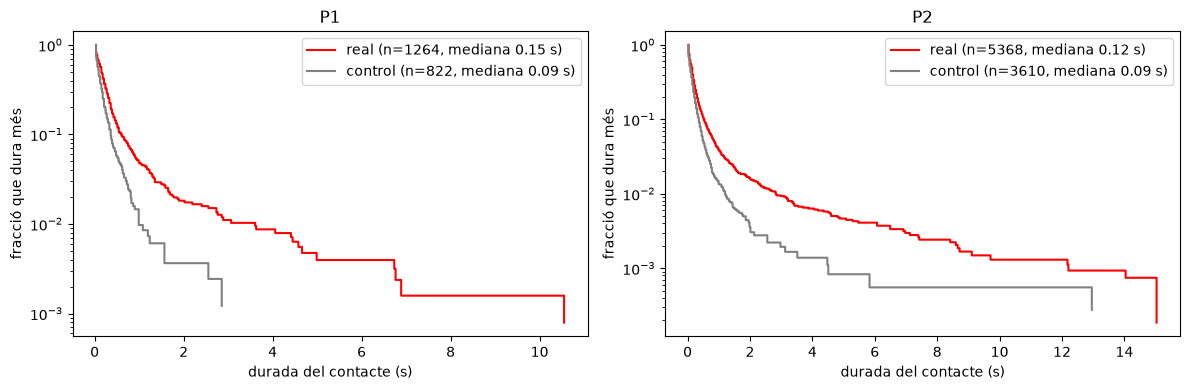

P1: durada mitjana real 0.309 s vs control 0.162 s,  Mann-Whitney p = 1.9e-14
P2: durada mitjana real 0.275 s vs control 0.165 s,  Mann-Whitney p = 2.17e-35


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, proj in enumerate(sorted(tots_episodis["projecte"].unique())):
    for cas, color in [("real", "r"), ("control", "gray")]:
        d = np.sort(tots_episodis[(tots_episodis["projecte"] == proj) & (tots_episodis["cas"] == cas)]["durada_s"].to_numpy())
        if len(d):
            ax[k].step(d, 1 - np.arange(len(d)) / len(d), where="post", color=color, label=f"{cas} (n={len(d)}, mediana {np.median(d):.2f} s)")
    ax[k].set_yscale("log"); ax[k].set_xlabel("durada del contacte (s)"); ax[k].set_ylabel("fracció que dura més")
    ax[k].set_title(proj); ax[k].legend()
plt.tight_layout(); plt.show()

for proj, g in tots_episodis.groupby("projecte"):
    a, b = g[g["cas"] == "real"]["durada_s"], g[g["cas"] == "control"]["durada_s"]
    print(f"{proj}: durada mitjana real {a.mean():.3f} s vs control {b.mean():.3f} s,  Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.3g}")

## 11. Conclusions

Resultats amb les 17 sèries (4 del projecte 1, 13 del projecte 2):

**Segmentació.** La UNet entrenada només amb dades simulades té F1 ≈ 0.99 a les simulacions. Al primer bloc de P1 s03, els 26 VLPs que troba també els detecta u-track al canal esquerre. Amb el filtre de pic mínim (`PIC_MIN`) i de persistència (`MIN_BLOCS`) surten entre 31 i 211 VLPs per vídeo.

**1. Les proteïnes s'acumulen sobre els VLPs.** L'enriquiment real és més alt que el del control en 15 de 17 sèries (fins a 6×, mentre que el control està entre 0.5 i 1.4). Les excepcions són P1 s03 i P2 s13, que queden com el control.

**2. Les proteïnes que interaccionen es mouen més lentament i de manera més confinada.**
* D mediana: 0.048 vs 0.153 µm²/s (P1) i 0.110 vs 0.211 µm²/s (P2), comparant *interacciona* amb *cap contacte*.
* En el control, les trajectòries "interacciona" **no** són més lentes (0.17 i 0.27 µm²/s). Per tant, la diferència no ve de cap biaix del mètode, sinó dels VLPs.
* El quocient D(interacciona)/D(cap contacte) és < 1 en 15/17 sèries i > 1 en totes les del control (Wilcoxon per sèries, p = 1.5·10⁻⁵).
* alpha baixa de 0.82 → 0.59 (P1) i de 0.89 → 0.76 (P2): el moviment és més subdifusiu (confinat).

**3. L'alentiment passa mentre la proteïna és sobre el VLP.** Els passos fets sobre el VLP tenen D_pas ≈ 0.12 (P1) i 0.10 µm²/s (P2). Els que la mateixa trajectòria fa fora del VLP (≈ 0.18 i 0.21) són iguals que els de les proteïnes que no toquen cap VLP. És a dir, no hi ha un canvi permanent de comportament: la proteïna s'alenteix només durant el contacte.

**4. Els contactes duren més que per atzar.** Durada mitjana de 0.31 vs 0.16 s (P1) i de 0.28 vs 0.17 s (P2), real vs control, amb una cua llarga d'episodis de diversos segons → unió transitòria.

**Limitacions / coses a revisar**
* El projecte 2 no té beads: es fa servir el registre del projecte 1 (error RMS 0.74 px, i la `TOLERANCIA` de 2 px el cobreix).
* Els p-valors de Mann-Whitney per trajectòria o per pas estan inflats (pseudo-rèplica). La prova fiable és la de per sèrie (Wilcoxon).
* Amb 4 sèries, el projecte 1 no té prou rèpliques per al test d'enriquiment.
* Els resultats depenen de `PIC_MIN`, `TOLERANCIA` i `MIN_CONTACTE`. Val la pena comprovar que les conclusions es mantenen si es canvien.
* Les màscares tenen una resolució temporal de `BLOC` = 5 frames (~0.15 s).